# Trabajo Práctico Integrador — Tecnología y Ambiente

**Alumno:** Kevin Lanatta  
**Docente:** Daniel Petruccelli  
**Proyecto:** Análisis predictivo del consumo eléctrico de un edificio de oficinas (`Panther_office_Karla`)  
**Fuente:** Building Data Genome 2  

El Notebook contiene código, resultados históricos y análisis de datos reales. La propuesta de intervención y su presupuesto son **escenarios académicos**, no actuaciones ejecutadas en el edificio.

## 1. Fuente de datos y metadatos

Se utiliza **Building Data Genome 2**, un conjunto de mediciones de edificios reales. Se selecciona `Panther_office_Karla`, un edificio de oficinas asociado al sitio Panther. Los archivos se obtienen desde GitHub Media para descargar su contenido y no un puntero de Git LFS.

Fuente: https://github.com/buds-lab/building-data-genome-project-2

In [ ]:

import pandas as pd

url = "https://media.githubusercontent.com/media/buds-lab/building-data-genome-project-2/master/data/metadata/metadata.csv"

edificios = pd.read_csv(url)

print("Dimensiones:", edificios.shape)
print("Columnas:", edificios.columns.tolist())
display(edificios.head())


Dimensiones: (1636, 32)
Columnas: ['building_id', 'site_id', 'building_id_kaggle', 'site_id_kaggle', 'primaryspaceusage', 'sub_primaryspaceusage', 'sqm', 'sqft', 'lat', 'lng', 'timezone', 'electricity', 'hotwater', 'chilledwater', 'steam', 'water', 'irrigation', 'solar', 'gas', 'industry', 'subindustry', 'heatingtype', 'yearbuilt', 'date_opened', 'numberoffloors', 'occupants', 'energystarscore', 'eui', 'site_eui', 'source_eui', 'leed_level', 'rating']


,building_id,site_id,building_id_kaggle,site_id_kaggle,primaryspaceusage,sub_primaryspaceusage,sqm,sqft,lat,lng,...,yearbuilt,date_opened,numberoffloors,occupants,energystarscore,eui,site_eui,source_eui,leed_level,rating
0,Panther_lodging_Dean,Panther,NaN,0.0,Lodging/residential,Residence Hall,508.8,5477.0,28.517689,-81.379039,...,1989.0,NaN,NaN,NaN,NaN,271,NaN,NaN,NaN,NaN
1,Panther_lodging_Shelia,Panther,NaN,0.0,Lodging/residential,Residence Hall,929.0,10000.0,28.517689,-81.379039,...,1992.0,NaN,NaN,NaN,NaN,62,NaN,NaN,NaN,NaN
2,Panther_lodging_Ricky,Panther,NaN,0.0,Lodging/residential,Residence Hall,483.1,5200.0,28.517689,-81.379039,...,2016.0,NaN,NaN,NaN,NaN,534,NaN,NaN,NaN,NaN
3,Panther_education_Rosalie,Panther,0.0,0.0,Education,Research,690.5,7432.0,28.517689,-81.379039,...,2008.0,NaN,NaN,NaN,NaN,276,NaN,NaN,NaN,NaN
4,Panther_education_Misty,Panther,1.0,0.0,Education,Research,252.7,2720.0,28.517689,-81.379039,...,2004.0,NaN,NaN,NaN,NaN,375,NaN,NaN,NaN,NaN


In [ ]:

# Verificar los valores de la columna electricity
print(edificios["electricity"].value_counts(dropna=False))

# Ver las categorías de edificios
print(edificios["primaryspaceusage"].value_counts())


electricity
Yes    1578
NaN      58
Name: count, dtype: int64
primaryspaceusage
Education                        617
Office                           307
Entertainment/public assembly    204
Lodging/residential              168
Public services                  166
Other                             29
Healthcare                        29
Parking                           24
Warehouse/storage                 15
Manufacturing/industrial          13
Retail                            12
Services                          11
Technology/science                 7
Food sales and service             6
Utility                            4
Religious worship                  3
Name: count, dtype: int64


In [ ]:

# Filtrar edificios de oficinas con medidor eléctrico
oficinas = edificios[
    (edificios["primaryspaceusage"] == "Office") &
    (edificios["electricity"] == "Yes")
]

# Mostrar cantidad de candidatos
print("Oficinas con medidor eléctrico:", len(oficinas))

# Mostrar los primeros 10 edificios
display(
    oficinas[
        ["building_id", "site_id", "sqm", "yearbuilt"]
    ].head(10)
)


Oficinas con medidor eléctrico: 296


,building_id,site_id,sqm,yearbuilt
16,Panther_office_Karla,Panther,2508.4,2010.0
23,Panther_office_Graham,Panther,7799.9,1974.0
25,Panther_office_Valarie,Panther,1416.8,1980.0
29,Panther_office_Larry,Panther,1738.9,2004.0
32,Panther_office_Jeane,Panther,654.3,1990.0
36,Panther_office_Jesus,Panther,9595.6,1969.0
37,Panther_office_Catherine,Panther,2504.0,2005.0
40,Panther_office_Garth,Panther,4919.9,2016.0
44,Panther_office_Shauna,Panther,4495.8,2005.0
51,Panther_office_Lois,Panther,1186.3,2013.0


## 2. Mediciones eléctricas y selección del edificio

El dataset contiene series horarias de electricidad. Se comprueba la disponibilidad y calidad de la serie temporal del edificio antes de procesarla.

In [ ]:

import pandas as pd

url = (
    "https://media.githubusercontent.com/media/buds-lab/"
    "building-data-genome-project-2/master/"
    "data/meters/raw/electricity.csv"
)

consumo = pd.read_csv(url)

print("Dimensiones:", consumo.shape)
print("Primeras columnas:", consumo.columns[:10].tolist())
display(consumo.head())


Dimensiones: (17544, 1579)
Primeras columnas: ['timestamp', 'Panther_parking_Lorriane', 'Panther_lodging_Cora', 'Panther_office_Hannah', 'Panther_lodging_Hattie', 'Panther_education_Teofila', 'Panther_education_Jerome', 'Panther_retail_Felix', 'Panther_parking_Asia', 'Panther_education_Misty']


,timestamp,Panther_parking_Lorriane,Panther_lodging_Cora,Panther_office_Hannah,Panther_lodging_Hattie,Panther_education_Teofila,Panther_education_Jerome,Panther_retail_Felix,Panther_parking_Asia,Panther_education_Misty,...,Cockatoo_public_Caleb,Cockatoo_education_Tyler,Cockatoo_public_Shad,Mouse_health_Buddy,Mouse_health_Modesto,Mouse_lodging_Vicente,Mouse_health_Justin,Mouse_health_Ileana,Mouse_health_Estela,Mouse_science_Micheal
0,2016-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,123.200,727.575,69.200,8.8224,370.0870,10.0,282.9965,26.0,135.0,168.2243
1,2016-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,126.475,731.200,66.275,17.6449,737.8260,30.0,574.9265,51.0,265.0,336.4486
2,2016-01-01 02:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,127.825,724.675,64.675,17.6449,729.9255,30.0,570.2780,50.0,272.0,336.4486
3,2016-01-01 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,130.475,737.375,65.875,17.6449,722.2620,20.0,561.1470,52.0,276.0,336.4486
4,2016-01-01 04:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,129.675,721.150,66.275,17.6449,719.1665,30.0,564.3695,50.0,280.0,336.4486


In [ ]:

# Seleccionar el edificio
edificio = "Panther_office_Karla"

# Extraer sus mediciones
datos = consumo[["timestamp", edificio]].copy()

# Renombrar columnas
datos.columns = ["fecha", "consumo_kwh"]

# Convertir fecha
datos["fecha"] = pd.to_datetime(datos["fecha"])

# Revisar resultados
print("Cantidad de registros:", len(datos))
print("Valores faltantes:", datos["consumo_kwh"].isna().sum())
print("Valores iguales a cero:", (datos["consumo_kwh"] == 0).sum())

display(datos.head(10))


Cantidad de registros: 17544
Valores faltantes: 11
Valores iguales a cero: 3377


,fecha,consumo_kwh
0,2016-01-01 00:00:00,0.0
1,2016-01-01 01:00:00,0.0
2,2016-01-01 02:00:00,0.0
3,2016-01-01 03:00:00,0.0
4,2016-01-01 04:00:00,0.0
5,2016-01-01 05:00:00,0.0
6,2016-01-01 06:00:00,0.0
7,2016-01-01 07:00:00,0.0
8,2016-01-01 08:00:00,0.0
9,2016-01-01 09:00:00,0.0


## 3. Auditoría de calidad y tratamiento de datos

Se revisan ceros, valores faltantes, duplicados, intervalos temporales y consumos negativos. Las mediciones en cero durante varios meses de 2016 no se interpretan como consumo real sin verificación, por lo que se estudia el período desde **junio de 2016**. Los 11 faltantes posteriores se estiman por interpolación lineal; los valores atípicos se conservan, porque no hay evidencia suficiente de error de sensor.

In [ ]:

# Crear variables temporales
datos["hora"] = datos["fecha"].dt.hour
datos["dia_semana"] = datos["fecha"].dt.dayofweek

# Porcentaje de ceros según la hora
ceros_por_hora = (
    datos.groupby("hora")["consumo_kwh"]
    .apply(lambda x: (x == 0).mean() * 100)
    .round(2)
)

print("Porcentaje de ceros por hora:")
print(ceros_por_hora)

# Comparación entre semana y fin de semana
datos["tipo_dia"] = datos["dia_semana"].apply(
    lambda x: "Fin de semana" if x >= 5 else "Lunes a viernes"
)

print("\nCeros por tipo de día:")
print(
    datos.groupby("tipo_dia")["consumo_kwh"]
    .apply(lambda x: (x == 0).mean() * 100)
    .round(2)
)


Porcentaje de ceros por hora:
hora
0     19.29
1     19.29
2     19.29
3     19.29
4     19.29
5     19.29
6     19.29
7     19.29
8     19.29
9     19.29
10    19.29
11    19.29
12    19.29
13    19.29
14    19.29
15    19.29
16    19.29
17    19.29
18    19.15
19    19.02
20    19.15
21    19.15
22    19.15
23    19.15
Name: consumo_kwh, dtype: float64

Ceros por tipo de día:
tipo_dia
Fin de semana      19.03
Lunes a viernes    19.34
Name: consumo_kwh, dtype: float64


In [ ]:

# Identificar bloques consecutivos de consumo cero
es_cero = datos["consumo_kwh"].eq(0)

grupos = es_cero.ne(es_cero.shift()).cumsum()

bloques = (
    datos[es_cero]
    .groupby(grupos[es_cero])
    .agg(
        inicio=("fecha", "min"),
        fin=("fecha", "max"),
        horas=("fecha", "count")
    )
    .sort_values("horas", ascending=False)
)

display(bloques.head(10))


,inicio,fin,horas
consumo_kwh,,,
1,2016-01-01 00:00:00,2016-05-01 18:00:00,2923
3,2016-05-01 20:00:00,2016-05-20 17:00:00,454


In [ ]:

# Analizar los datos desde junio de 2016
datos_validos = datos[
    datos["fecha"] >= "2016-06-01"
].copy()

print("Registros:", len(datos_validos))
print("Valores faltantes:", datos_validos["consumo_kwh"].isna().sum())
print("Valores en cero:", (datos_validos["consumo_kwh"] == 0).sum())
print("Consumo mínimo:", datos_validos["consumo_kwh"].min())
print("Consumo máximo:", datos_validos["consumo_kwh"].max())


Registros: 13896
Valores faltantes: 11
Valores en cero: 0
Consumo mínimo: 11.7623
Consumo máximo: 105.1403


In [ ]:

# Comprobar continuidad de las mediciones
print("Fechas duplicadas:",
      datos_validos["fecha"].duplicated().sum())

diferencias = datos_validos["fecha"].diff()

print("Intervalos distintos de una hora:",
      (diferencias.dropna() != pd.Timedelta(hours=1)).sum())

print("Valores negativos:",
      (datos_validos["consumo_kwh"] < 0).sum())


Fechas duplicadas: 0
Intervalos distintos de una hora: 0
Valores negativos: 0


In [ ]:

# Ordenar los datos por fecha
datos_limpios = datos_validos.sort_values("fecha").copy()

# Completar valores faltantes mediante interpolación
datos_limpios["consumo_kwh"] = (
    datos_limpios["consumo_kwh"]
    .interpolate(method="linear", limit_area="inside")
)

# Comprobar resultados
print("Valores faltantes restantes:",
      datos_limpios["consumo_kwh"].isna().sum())

print("\nResumen estadístico:")
print(datos_limpios["consumo_kwh"].describe())


Valores faltantes restantes: 0

Resumen estadístico:
count    13896.000000
mean        35.494443
std         15.918143
min         11.762300
25%         19.683800
50%         36.127000
75%         46.689000
max        105.140300
Name: consumo_kwh, dtype: float64
Valores faltantes restantes: 0

Resumen estadístico:
count    13896.000000
mean        35.494443
std         15.918143
min         11.762300
25%         19.683800
50%         36.127000
75%         46.689000
max        105.140300
Name: consumo_kwh, dtype: float64


In [ ]:

# Calcular los cuartiles
Q1 = datos_limpios["consumo_kwh"].quantile(0.25)
Q3 = datos_limpios["consumo_kwh"].quantile(0.75)

IQR = Q3 - Q1

# Establecer límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Identificar posibles valores atípicos
outliers = datos_limpios[
    (datos_limpios["consumo_kwh"] < limite_inferior) |
    (datos_limpios["consumo_kwh"] > limite_superior)
]

print("Límite inferior:", round(limite_inferior, 2))
print("Límite superior:", round(limite_superior, 2))
print("Cantidad de posibles outliers:", len(outliers))

display(outliers[["fecha", "consumo_kwh"]].head(10))


Límite inferior: -20.82
Límite superior: 87.2
Cantidad de posibles outliers: 36


,fecha,consumo_kwh
8957,2017-01-08 05:00:00,87.8569
8971,2017-01-08 19:00:00,87.3769
8975,2017-01-08 23:00:00,93.4980
8976,2017-01-09 00:00:00,87.6169
8977,2017-01-09 01:00:00,87.3769
8979,2017-01-09 03:00:00,89.8974
8980,2017-01-09 04:00:00,90.9776
8981,2017-01-09 05:00:00,88.0970
8983,2017-01-09 07:00:00,90.0174
8985,2017-01-09 09:00:00,91.9378


In [ ]:

# Agrupar los valores atípicos por fecha
outliers_por_dia = (
    outliers.assign(dia=outliers["fecha"].dt.date)
    .groupby("dia")
    .agg(
        cantidad=("consumo_kwh", "count"),
        consumo_maximo=("consumo_kwh", "max")
    )
    .sort_values("cantidad", ascending=False)
)

display(outliers_por_dia.head(15))


,cantidad,consumo_maximo
dia,,
2017-01-09,8,91.9378
2017-03-16,6,101.0595
2017-03-17,5,105.1403
2017-03-15,4,91.6977
2017-01-08,3,93.4980
2017-12-12,2,90.4975
2017-12-11,2,91.6977
2017-01-31,1,87.7369
2017-01-10,1,88.0970


## 4. Datos meteorológicos y análisis exploratorio

Se cruza la temperatura exterior del sitio `Panther` con el consumo eléctrico usando fecha y hora. Los picos de invierno son compatibles con una mayor demanda de climatización, pero **correlación no implica causalidad**. Se observa una relación no lineal: la correlación lineal por sí sola no la captura.

In [ ]:

import pandas as pd

url_clima = (
    "https://media.githubusercontent.com/media/buds-lab/"
    "building-data-genome-project-2/master/"
    "data/weather/weather.csv"
)

clima = pd.read_csv(url_clima)

print("Dimensiones:", clima.shape)
print("Columnas:", clima.columns.tolist())
display(clima.head())


Dimensiones: (331166, 10)
Columnas: ['timestamp', 'site_id', 'airTemperature', 'cloudCoverage', 'dewTemperature', 'precipDepth1HR', 'precipDepth6HR', 'seaLvlPressure', 'windDirection', 'windSpeed']


,timestamp,site_id,airTemperature,cloudCoverage,dewTemperature,precipDepth1HR,precipDepth6HR,seaLvlPressure,windDirection,windSpeed
0,2016-01-01 00:00:00,Panther,19.4,NaN,19.4,0.0,NaN,NaN,0.0,0.0
1,2016-01-01 01:00:00,Panther,21.1,6.0,21.1,-1.0,NaN,1019.4,0.0,0.0
2,2016-01-01 02:00:00,Panther,21.1,NaN,21.1,0.0,NaN,1018.8,210.0,1.5
3,2016-01-01 03:00:00,Panther,20.6,NaN,20.0,0.0,NaN,1018.1,0.0,0.0
4,2016-01-01 04:00:00,Panther,21.1,NaN,20.6,0.0,NaN,1019.0,290.0,1.5


In [ ]:

# Seleccionar temperaturas del sitio Panther
clima_panther = clima[
    clima["site_id"] == "Panther"
][["timestamp", "airTemperature"]].copy()

# Convertir fecha
clima_panther["fecha"] = pd.to_datetime(
    clima_panther["timestamp"]
)

# Renombrar la temperatura
clima_panther = clima_panther.rename(
    columns={"airTemperature": "temperatura_c"}
)

# Unir consumo y temperatura por fecha y hora
datos_completos = datos_limpios.merge(
    clima_panther[["fecha", "temperatura_c"]],
    on="fecha",
    how="left"
)

print("Registros unidos:", len(datos_completos))
print(
    "Temperaturas faltantes:",
    datos_completos["temperatura_c"].isna().sum()
)

display(
    datos_completos[
        ["fecha", "consumo_kwh", "temperatura_c"]
    ].head()
)


Registros unidos: 13896
Temperaturas faltantes: 0


,fecha,consumo_kwh,temperatura_c
0,2016-06-01 00:00:00,18.8436,22.8
1,2016-06-01 01:00:00,18.9637,22.8
2,2016-06-01 02:00:00,18.8436,23.3
3,2016-06-01 03:00:00,18.8436,22.2
4,2016-06-01 04:00:00,19.0837,22.8


In [ ]:

# Seleccionar los días del aumento de consumo
marzo = datos_completos[
    (datos_completos["fecha"] >= "2017-03-15") &
    (datos_completos["fecha"] < "2017-03-18")
].copy()

# Resumir por día
marzo["dia"] = marzo["fecha"].dt.date

resumen_marzo = marzo.groupby("dia").agg(
    temperatura_minima=("temperatura_c", "min"),
    temperatura_media=("temperatura_c", "mean"),
    consumo_promedio=("consumo_kwh", "mean"),
    consumo_maximo=("consumo_kwh", "max")
).round(2)

display(resumen_marzo)


,temperatura_minima,temperatura_media,consumo_promedio,consumo_maximo
dia,,,,
2017-03-15,7.8,11.27,59.70,91.70
2017-03-16,3.9,11.00,61.88,101.06
2017-03-17,6.7,14.55,63.73,105.14


In [ ]:

# Calcular correlación entre temperatura y consumo
correlacion = datos_completos[
    ["temperatura_c", "consumo_kwh"]
].corr()

print("Correlación entre temperatura y consumo:")
print(correlacion)



Correlación entre temperatura y consumo:
               temperatura_c  consumo_kwh
temperatura_c       1.000000    -0.036952
consumo_kwh        -0.036952     1.000000


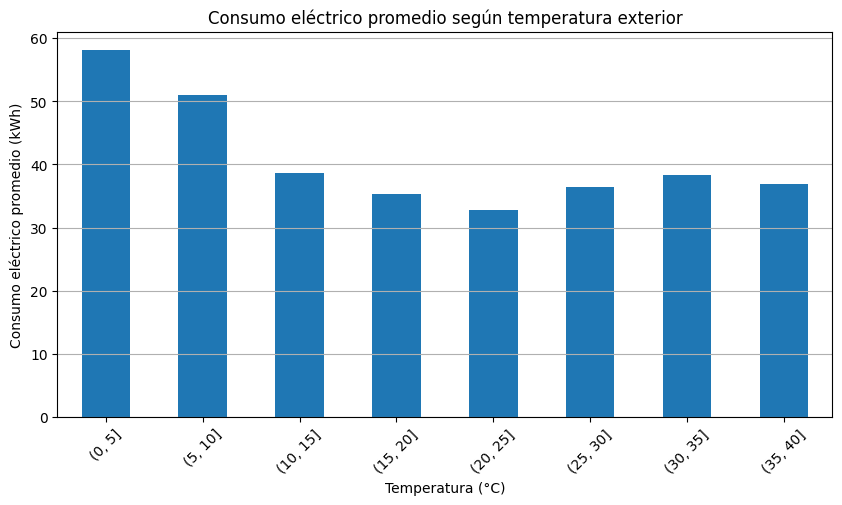

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

# Crear intervalos de temperatura de 5 °C
datos_completos["rango_temp"] = (
    pd.cut(
        datos_completos["temperatura_c"],
        bins=range(-5, 46, 5)
    )
)

# Calcular consumo promedio por intervalo
consumo_por_temp = (
    datos_completos
    .groupby("rango_temp", observed=True)["consumo_kwh"]
    .mean()
)

# Visualizar
plt.figure(figsize=(10, 5))
consumo_por_temp.plot(kind="bar")

plt.title("Consumo eléctrico promedio según temperatura exterior")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Consumo eléctrico promedio (kWh)")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()


In [ ]:

# Contar registros por intervalo de temperatura
cantidad_por_temp = (
    datos_completos
    .groupby("rango_temp", observed=True)
    ["consumo_kwh"]
    .count()
)

display(cantidad_por_temp)


,consumo_kwh
rango_temp,
"(0, 5]",37
"(5, 10]",233
"(10, 15]",828
"(15, 20]",2349
"(20, 25]",5035
"(25, 30]",3974
"(30, 35]",1429
"(35, 40]",11


## 5. Modelo predictivo: entrenamiento y evaluación

Objetivo: estimar el consumo eléctrico horario con variables de calendario, temperatura y consumos anteriores. Se separa entrenamiento y prueba **en orden cronológico**, sin mezclar registros futuros en el entrenamiento. Para reproducir una predicción de la hora siguiente en producción haría falta un pronóstico de temperatura (aquí se utiliza la temperatura observada de esa hora).

In [ ]:

# Ordenar cronológicamente
modelo_datos = datos_completos.sort_values("fecha").copy()

# Crear variables temporales
modelo_datos["hora"] = modelo_datos["fecha"].dt.hour
modelo_datos["dia_semana"] = modelo_datos["fecha"].dt.dayofweek
modelo_datos["mes"] = modelo_datos["fecha"].dt.month

# Definir variables predictoras y objetivo
variables = ["hora", "dia_semana", "mes", "temperatura_c"]

X = modelo_datos[variables]
y = modelo_datos["consumo_kwh"]

print("Variables predictoras:", X.columns.tolist())
print("Cantidad de registros:", len(X))
print("Valores faltantes:", X.isna().sum().sum())


Variables predictoras: ['hora', 'dia_semana', 'mes', 'temperatura_c']
Cantidad de registros: 13896
Valores faltantes: 0


In [ ]:

# Dividir los datos cronológicamente
corte = int(len(X) * 0.8)

X_train = X.iloc[:corte]
X_test = X.iloc[corte:]

y_train = y.iloc[:corte]
y_test = y.iloc[corte:]

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))

print("Inicio entrenamiento:",
      modelo_datos["fecha"].iloc[0])
print("Fin entrenamiento:",
      modelo_datos["fecha"].iloc[corte - 1])

print("Inicio prueba:",
      modelo_datos["fecha"].iloc[corte])
print("Fin prueba:",
      modelo_datos["fecha"].iloc[-1])


Registros de entrenamiento: 11116
Registros de prueba: 2780
Inicio entrenamiento: 2016-06-01 00:00:00
Fin entrenamiento: 2017-09-07 03:00:00
Inicio prueba: 2017-09-07 04:00:00
Fin prueba: 2017-12-31 23:00:00


In [ ]:

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Crear el modelo
modelo = DecisionTreeRegressor(
    max_depth=5,
    min_samples_leaf=20,
    random_state=42
)

# Entrenar con datos históricos
modelo.fit(X_train, y_train)

# Predecir el consumo en el conjunto de prueba
predicciones = modelo.predict(X_test)

# Evaluar el modelo
mae = mean_absolute_error(y_test, predicciones)
rmse = np.sqrt(mean_squared_error(y_test, predicciones))
r2 = r2_score(y_test, predicciones)

print("MAE:", round(mae, 2), "kWh")
print("RMSE:", round(rmse, 2), "kWh")
print("R²:", round(r2, 4))


MAE: 9.13 kWh
RMSE: 12.4 kWh
R²: 0.4052


## 6. Mejora del modelo con historial de consumo

Se añaden retardos de 1 h y 24 h, usando solamente el consumo anterior al instante objetivo. Se comparan árbol de decisión, persistencia de la última hora y Random Forest.

In [ ]:

# Crear variables de consumo histórico
modelo_datos["consumo_anterior"] = (
    modelo_datos["consumo_kwh"].shift(1)
)

modelo_datos["consumo_24h"] = (
    modelo_datos["consumo_kwh"].shift(24)
)

# Eliminar solamente las filas iniciales
# que no tienen historial suficiente
modelo_datos_v2 = modelo_datos.dropna(
    subset=["consumo_anterior", "consumo_24h"]
).copy()

# Definir las variables del nuevo modelo
variables_v2 = [
    "hora",
    "dia_semana",
    "mes",
    "temperatura_c",
    "consumo_anterior",
    "consumo_24h"
]

X_v2 = modelo_datos_v2[variables_v2]
y_v2 = modelo_datos_v2["consumo_kwh"]

print("Registros disponibles:", len(X_v2))
print("Variables:", X_v2.columns.tolist())
print("Valores faltantes:", X_v2.isna().sum().sum())


Registros disponibles: 13872
Variables: ['hora', 'dia_semana', 'mes', 'temperatura_c', 'consumo_anterior', 'consumo_24h']
Valores faltantes: 0


In [ ]:

# Mantener la misma división temporal del modelo anterior
fecha_corte = pd.Timestamp("2017-09-07 04:00:00")

train_v2 = modelo_datos_v2["fecha"] < fecha_corte
test_v2 = modelo_datos_v2["fecha"] >= fecha_corte

X_train_v2 = X_v2.loc[train_v2]
X_test_v2 = X_v2.loc[test_v2]

y_train_v2 = y_v2.loc[train_v2]
y_test_v2 = y_v2.loc[test_v2]

# Entrenar el segundo modelo
modelo_v2 = DecisionTreeRegressor(
    max_depth=5,
    min_samples_leaf=20,
    random_state=42
)

modelo_v2.fit(X_train_v2, y_train_v2)

# Realizar predicciones
predicciones_v2 = modelo_v2.predict(X_test_v2)

# Calcular métricas
mae_v2 = mean_absolute_error(y_test_v2, predicciones_v2)
rmse_v2 = np.sqrt(
    mean_squared_error(y_test_v2, predicciones_v2)
)
r2_v2 = r2_score(y_test_v2, predicciones_v2)

print("Entrenamiento:", len(X_train_v2))
print("Prueba:", len(X_test_v2))

print("MAE:", round(mae_v2, 2), "kWh")
print("RMSE:", round(rmse_v2, 2), "kWh")
print("R²:", round(r2_v2, 4))


Entrenamiento: 11092
Prueba: 2780
MAE: 2.88 kWh
RMSE: 5.06 kWh
R²: 0.9009


In [ ]:

# Modelo base: usar el consumo de la hora anterior
predicciones_base = X_test_v2["consumo_anterior"]

# Evaluar modelo base
mae_base = mean_absolute_error(
    y_test_v2, predicciones_base
)

rmse_base = np.sqrt(
    mean_squared_error(y_test_v2, predicciones_base)
)

r2_base = r2_score(
    y_test_v2, predicciones_base
)

print("MODELO BASE")
print("MAE:", round(mae_base, 2), "kWh")
print("RMSE:", round(rmse_base, 2), "kWh")
print("R²:", round(r2_base, 4))


MODELO BASE
MAE: 2.55 kWh
RMSE: 5.53 kWh
R²: 0.8815


## 7. Random Forest y comparación

El modelo Random Forest con historial de consumo fue el mejor de los métodos ensayados. Según la ejecución conservada: MAE = **1,88 kWh**, RMSE = **3,67 kWh**, R² = **0,9478**. Estas métricas son de la partición de prueba, no de un despliegue real.

In [ ]:

from sklearn.ensemble import RandomForestRegressor

# Crear el modelo Random Forest
modelo_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Entrenar
modelo_rf.fit(X_train_v2, y_train_v2)

# Predecir
predicciones_rf = modelo_rf.predict(X_test_v2)

# Evaluar
mae_rf = mean_absolute_error(y_test_v2, predicciones_rf)
rmse_rf = np.sqrt(
    mean_squared_error(y_test_v2, predicciones_rf)
)
r2_rf = r2_score(y_test_v2, predicciones_rf)

print("RANDOM FOREST")
print("MAE:", round(mae_rf, 2), "kWh")
print("RMSE:", round(rmse_rf, 2), "kWh")
print("R²:", round(r2_rf, 4))


RANDOM FOREST
MAE: 1.88 kWh
RMSE: 3.67 kWh
R²: 0.9478


## 8. Medición estimada de huella computacional

Se utiliza CodeCarbon para estimar energía y emisiones durante **una nueva ejecución** del entrenamiento. Los resultados pueden cambiar según el entorno de Colab. Una ejecución previa dio aproximadamente **0,000201 kWh** y **0,000129 kg CO₂e**. Estos datos no representan el ciclo completo de vida del software.

In [ ]:

!pip install -q codecarbon


In [ ]:

from codecarbon import EmissionsTracker
from sklearn.ensemble import RandomForestRegressor

# Iniciar la medición
tracker = EmissionsTracker(
    project_name="TPI_Tecnologia_Ambiente",
    output_dir=".",
    log_level="error"
)

tracker.start()

# Entrenar nuevamente Random Forest
modelo_rf_carbono = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

modelo_rf_carbono.fit(X_train_v2, y_train_v2)

# Finalizar la medición
emisiones = tracker.stop()

print("Emisiones estimadas:", emisiones, "kg CO2eq")


[codecarbon WARNING @ 21:53:10] Multiple instances of codecarbon are allowed to run at the same time.


Emisiones estimadas: 0.0001292101489096395 kg CO2eq


In [ ]:

import pandas as pd

# Leer el archivo generado por CodeCarbon
emisiones_df = pd.read_csv("emissions.csv")

# Mostrar los datos de la última ejecución
columnas = [
    "project_name",
    "duration",
    "energy_consumed",
    "emissions"
]

display(emisiones_df[columnas].tail(1))


,project_name,duration,energy_consumed,emissions
0,TPI_Tecnologia_Ambiente,3.40325,0.000201,0.000129


## 9. Interpretabilidad y análisis de consumos

Se estudia la importancia de variables y el consumo por hora y tipo de día. La importancia de características del bosque aleatorio es **predictiva**, no un efecto causal comprobado.

In [ ]:

# Importancia de las variables de Random Forest
importancias = pd.DataFrame({
    "variable": X_train_v2.columns,
    "importancia": modelo_rf.feature_importances_
})

importancias = importancias.sort_values(
    "importancia", ascending=False
)

display(importancias.round(4))


,variable,importancia
4,consumo_anterior,0.9430
0,hora,0.0255
5,consumo_24h,0.0199
3,temperatura_c,0.0053
1,dia_semana,0.0050
2,mes,0.0013


In [ ]:

# Entrenar Random Forest sin temperatura
variables_sin_temp = [
    "hora",
    "dia_semana",
    "mes",
    "consumo_anterior",
    "consumo_24h"
]

modelo_sin_temp = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

modelo_sin_temp.fit(
    X_train_v2[variables_sin_temp],
    y_train_v2
)

pred_sin_temp = modelo_sin_temp.predict(
    X_test_v2[variables_sin_temp]
)

print("RANDOM FOREST SIN TEMPERATURA")
print("MAE:", round(mean_absolute_error(y_test_v2, pred_sin_temp), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_v2, pred_sin_temp)), 2))
print("R²:", round(r2_score(y_test_v2, pred_sin_temp), 4))


RANDOM FOREST SIN TEMPERATURA
MAE: 1.91
RMSE: 3.76
R²: 0.9453


In [39]:

# Comparar el consumo según la hora
consumo_por_hora = (
    datos_limpios
    .groupby(datos_limpios["fecha"].dt.hour)
    ["consumo_kwh"]
    .mean()
    .round(2)
)

display(consumo_por_hora)


,consumo_kwh
fecha,
0,27.34
1,27.62
2,27.89
3,28.36
4,28.58
5,28.55
6,36.02
7,37.55
8,39.42


In [40]:

# Identificar tipo de día
datos_limpios["tipo_dia"] = (
    datos_limpios["fecha"].dt.dayofweek
    .apply(lambda x: "Fin de semana" if x >= 5
           else "Lunes a viernes")
)

# Calcular consumo promedio por tipo de día
comparacion_dias = (
    datos_limpios.groupby("tipo_dia")["consumo_kwh"]
    .agg(["mean", "min", "max"])
    .round(2)
)

display(comparacion_dias)


,mean,min,max
tipo_dia,,,
Fin de semana,26.60,12.36,93.50
Lunes a viernes,39.07,11.76,105.14


In [41]:

# Seleccionar solamente fines de semana
fines_semana = datos_completos[
    datos_completos["fecha"].dt.dayofweek >= 5
].copy()

# Identificar los 10 consumos más elevados
picos_fin_semana = fines_semana.nlargest(
    10, "consumo_kwh"
)

display(
    picos_fin_semana[
        ["fecha", "consumo_kwh", "temperatura_c"]
    ]
)


,fecha,consumo_kwh,temperatura_c
5327,2017-01-08 23:00:00,93.4980,5.0
5309,2017-01-08 05:00:00,87.8569,3.9
5323,2017-01-08 19:00:00,87.3769,7.2
5307,2017-01-08 03:00:00,86.8968,5.0
5311,2017-01-08 07:00:00,86.5367,2.2
5310,2017-01-08 06:00:00,86.1766,2.2
5326,2017-01-08 22:00:00,85.4565,5.6
5308,2017-01-08 04:00:00,84.2563,4.4
5817,2017-01-29 09:00:00,83.0560,9.4
5304,2017-01-08 00:00:00,82.3359,6.1


In [42]:

# Comparar consumos reales y predichos
evaluacion = modelo_datos_v2.loc[test_v2, ["fecha"]].copy()

evaluacion["consumo_real"] = y_test_v2.to_numpy()
evaluacion["consumo_predicho"] = predicciones_rf

# Calcular diferencia
evaluacion["desviacion"] = (
    evaluacion["consumo_real"] -
    evaluacion["consumo_predicho"]
)

# Mostrar las 10 desviaciones positivas más grandes
display(
    evaluacion.nlargest(10, "desviacion")[
        ["fecha", "consumo_real",
         "consumo_predicho", "desviacion"]
    ].round(2)
)


,fecha,consumo_real,consumo_predicho,desviacion
13422,2017-12-12 06:00:00,72.25,33.89,38.37
13158,2017-12-01 06:00:00,73.93,35.86,38.07
12798,2017-11-16 06:00:00,74.77,37.01,37.76
13398,2017-12-11 06:00:00,71.17,37.84,33.34
13470,2017-12-14 06:00:00,69.01,37.95,31.06
13446,2017-12-13 06:00:00,67.09,37.79,29.31
13399,2017-12-11 07:00:00,91.70,69.97,21.72
13447,2017-12-13 07:00:00,87.74,67.36,20.37
13471,2017-12-14 07:00:00,88.34,68.81,19.53
12415,2017-10-31 07:00:00,69.97,50.95,19.03


## 10. Demanda anual y alternativa solar

Se suma el consumo de los 8.760 registros horarios de 2017. El resultado en la ejecución documentada fue **313.654,41 kWh**. Una simulación externa en PVWatts para Orlando, potencia **40 kW**, arroja **61.717 kWh/año**, equivalentes al **19,68%** de la demanda anual medida. Es una equivalencia de energía anual, no una cobertura horaria o autoconsumo demostrado. Fuente: https://pvwatts.nlr.gov/

In [43]:

# Seleccionar el año completo 2017
consumo_2017 = datos_limpios[
    datos_limpios["fecha"].dt.year == 2017
].copy()

# Comprobar registros y calcular consumo anual
registros = len(consumo_2017)
consumo_anual = consumo_2017["consumo_kwh"].sum()
consumo_mensual = consumo_2017.groupby(
    consumo_2017["fecha"].dt.month
)["consumo_kwh"].sum()

print("Registros de 2017:", registros)
print("Consumo anual:", round(consumo_anual, 2), "kWh")

print("\nConsumo mensual (kWh):")
display(consumo_mensual.round(2))


Registros de 2017: 8760
Consumo anual: 313654.41 kWh

Consumo mensual (kWh):


,consumo_kwh
fecha,
1,43112.44
2,38990.00
3,35787.00
4,21275.78
5,21849.38
6,21221.17
7,21493.75
8,22765.87
9,19161.22


## 11. Plan Tecnológico propuesto

**Objetivo:** utilizar las estimaciones del modelo para orientar una auditoría y reducir consumos innecesarios en el edificio.

| Acción propuesta | Justificación | Indicador de seguimiento |
|---|---|---|
| Monitoreo y alertas de desviación | El modelo estima consumo horario y se observaron diferencias grandes en algunos períodos | Alertas verificadas / alertas totales |
| Auditoría de cargas fuera de horario | Existe consumo nocturno persistente que requiere conocer qué equipos permanecen activos | Consumo nocturno normalizado (kWh) |
| Revisión de climatización | Se observó alto consumo durante episodios fríos, sin causa confirmada | Consumo por rango térmico y ocupación |
| Estudio de fotovoltaica de 40 kW | PVWatts estima generación anual equivalente al 19,68% de la demanda histórica de 2017 | Generación solar simulada o medida (kWh/año) |

Antes de implementar se requiere inventariar equipos reales, verificar características del techo, costos y condiciones de conexión. Los ahorros requieren un escenario explícito y no se derivan automáticamente de la precisión del modelo. La información económica detallada se encuentra en el informe técnico en PDF.


## 12. Uso de herramientas de IA y revisión crítica

Se utilizó ChatGPT como asistencia para estructurar consultas en Pandas, la limpieza, el modelado y la explicación de resultados. **Para cumplir el registro íntegro de prompts exigido por la cátedra, adjuntar o transcribir los textos exactos de las consultas realizadas**, sin inventar interacciones. El diálogo original puede utilizarse para recuperar los pedidos.

**Problemas y supuestos detectados durante el proceso (comprobados en el desarrollo):**

1. **Descarga incorrecta de GitHub/LFS.** Una primera URL devolvía un archivo-puntero (`version https://git-lfs.github.com/spec/v1`) y provocó `KeyError: 'electricity'`. Se corrigió utilizando el enlace de contenido real de GitHub Media y verificando las 32 columnas de metadatos.
2. **Interpretación insuficiente de correlación.** Un coeficiente de Pearson cercano a cero (−0,037) podía sugerir ausencia de relación, pero el análisis por rangos de temperatura mostró una asociación **no lineal**; se corrigió la interpretación y se evitó atribuir causalidad a la calefacción.
3. **Límite del pronóstico.** El modelo usa temperatura observada de la hora estimada y consumos pasados; no debe presentarse como un pronóstico operativo futuro sin disponer de pronósticos meteorológicos y consumos previos en tiempo real.

**Referencias principales:**
- Repositorio Building Data Genome 2: https://github.com/buds-lab/building-data-genome-project-2
- Publicación científica: https://pmc.ncbi.nlm.nih.gov/articles/PMC7591488/
- PVWatts: https://pvwatts.nlr.gov/
- CodeCarbon: https://mlco2.github.io/codecarbon/

**Estado de entrega:** conservar los resultados ejecutados, verificar los vínculos y registrar los prompts originales antes de enviar.
